# Metrics: every score the teacher may ask for
Run cell 1 (it makes a small model), then copy the cell you need.

| Teacher asks | Type | Use |
|---|---|---|
| accuracy | class | `accuracy_score` |
| precision | class | `precision_score` |
| recall / sensitivity | class | `recall_score` |
| F1 | class | `f1_score` |
| confusion matrix | class | `confusion_matrix`, `ConfusionMatrixDisplay` |
| all of them at once | class | `classification_report` |
| ROC / AUC | class | `roc_auc_score`, `RocCurveDisplay` |
| R² | reg | `r2_score` |
| MAE | reg | `mean_absolute_error` |
| MSE | reg | `mean_squared_error` |
| RMSE | reg | `np.sqrt(mean_squared_error(...))` |
| MAPE (%) | reg | `mean_absolute_percentage_error` |

## 1. Setup: imports + one classifier + one regressor

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

# ---- classification metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, RocCurveDisplay)
# ---- regression metrics
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error)

df = pd.read_csv("../titanic.csv")
cols = ["Age", "Pclass", "SibSp"]
df = df[cols + ["Survived", "Fare"]].dropna()
x_train, x_test, y_train, y_test = train_test_split(df[cols], df[["Survived", "Fare"]], test_size=0.2, random_state=42)

clf = HistGradientBoostingClassifier(random_state=42).fit(x_train, y_train["Survived"])
reg = HistGradientBoostingRegressor(random_state=42).fit(x_train, y_train["Fare"])

y_true, y_pred = y_test["Survived"], clf.predict(x_test)     # class
r_true, r_pred = y_test["Fare"], reg.predict(x_test)         # number

# Part A: Classification

## 2. Accuracy, precision, recall, F1
- **accuracy** = how many predictions are right overall
- **precision** = of the ones I said "yes", how many really are yes
- **recall** = of the real "yes", how many I found
- **F1** = balance of precision and recall (good when classes are imbalanced)

In [2]:
print("accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("precision:", round(precision_score(y_true, y_pred), 4))
print("recall   :", round(recall_score(y_true, y_pred), 4))
print("F1       :", round(f1_score(y_true, y_pred), 4))

accuracy : 0.6713
precision: 0.6216
recall   : 0.4107
F1       : 0.4946


> **3+ classes?** add `average="macro"` (every class counts the same)
> or `average="weighted"` (bigger classes count more):
> `precision_score(y_true, y_pred, average="macro")`.
> Without it you get the error **"Target is multiclass but average='binary'"**.

## 3. Confusion matrix
```
                 predicted 0   predicted 1
actual 0             TN            FP
actual 1             FN            TP
```
The diagonal (TN, TP) is correct; the rest are mistakes.

[[73 14]
 [33 23]]
TN 73 FP 14 FN 33 TP 23


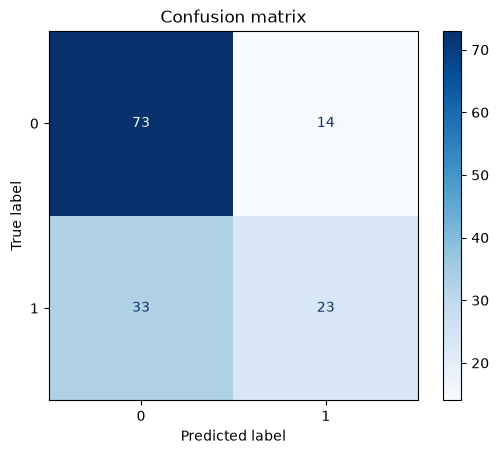

In [3]:
cm = confusion_matrix(y_true, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()          # only for 2 classes
print("TN", tn, "FP", fp, "FN", fn, "TP", tp)

ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

## 4. All scores in one table (classification_report)

In [4]:
print(classification_report(y_true, y_pred))
# support = how many real rows of that class

              precision    recall  f1-score   support

           0       0.69      0.84      0.76        87
           1       0.62      0.41      0.49        56

    accuracy                           0.67       143
   macro avg       0.66      0.62      0.63       143
weighted avg       0.66      0.67      0.65       143



## 5. ROC curve and AUC
AUC: 1.0 = perfect, 0.5 = random guessing. It needs **probabilities** (`predict_proba`), not classes.

AUC: 0.7176


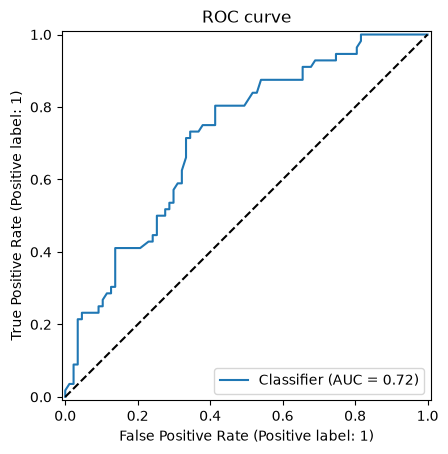

In [5]:
prob = clf.predict_proba(x_test)[:, 1]          # probability of class 1
print("AUC:", round(roc_auc_score(y_true, prob), 4))
# 3+ classes: roc_auc_score(y_true, clf.predict_proba(x_test), multi_class="ovr")

RocCurveDisplay.from_predictions(y_true, prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC curve")
plt.show()

## 6. Same scores by hand (if the teacher says no sklearn)

In [6]:
t, p = np.array(y_true), np.array(y_pred)
tp = ((p == 1) & (t == 1)).sum()
tn = ((p == 0) & (t == 0)).sum()
fp = ((p == 1) & (t == 0)).sum()
fn = ((p == 0) & (t == 1)).sum()

accuracy = (tp + tn) / len(t)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print(f"accuracy {accuracy:.4f}  precision {precision:.4f}  recall {recall:.4f}  F1 {f1:.4f}")

accuracy 0.6713  precision 0.6216  recall 0.4107  F1 0.4946


# Part B: Regression

## 7. R², MAE, MSE, RMSE, MAPE
- **R²** = 1 is perfect, 0 = no better than guessing the mean (higher is better)
- **MAE** = average error, in the same unit as y (lower is better)
- **MSE** = average squared error, so big mistakes count a lot (lower is better)
- **RMSE** = √MSE, back in the same unit as y (lower is better)
- **MAPE** = average error in % (lower is better; breaks if y has 0)

In [7]:
print("R2  :", round(r2_score(r_true, r_pred), 4))
print("MAE :", round(mean_absolute_error(r_true, r_pred), 4))
print("MSE :", round(mean_squared_error(r_true, r_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(r_true, r_pred)), 4))
# MAPE divides by y, so if y has 0 it explodes -> skip the 0 rows
ok = r_true != 0
print("MAPE:", round(mean_absolute_percentage_error(r_true[ok], r_pred[ok]) * 100, 2), "%  (rows with y = 0 skipped)")

R2  : 0.1858
MAE : 21.1666
MSE : 3389.5521
RMSE: 58.2199
MAPE: 65.09 %  (rows with y = 0 skipped)


## 8. Same scores by hand (Q1 is from scratch, so use this there)

In [8]:
t, p = np.array(r_true), np.array(r_pred)
r2 = 1 - ((t - p) ** 2).sum() / ((t - t.mean()) ** 2).sum()
mae = np.abs(t - p).mean()
mse = ((t - p) ** 2).mean()
rmse = np.sqrt(mse)
print(f"R2 {r2:.4f}  MAE {mae:.2f}  MSE {mse:.2f}  RMSE {rmse:.2f}")

R2 0.1858  MAE 21.17  MSE 3389.55  RMSE 58.22


# Part C: Put more scores into your ranking tables

## 9. Classification ranking with every score
Paste after the classifier loop in Q2 (it uses `classifiers`, `x_train`, `x_test` from there).

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

classifiers = [
    ("Logistic", LogisticRegression(max_iter=1000)),
    ("KNN", KNeighborsClassifier()),
    ("DecisionTree", DecisionTreeClassifier(max_depth=4)),
    ("HistGB", HistGradientBoostingClassifier(random_state=42)),
]
rows = []
for name, model in classifiers:
    p = model.fit(x_train, y_train["Survived"]).predict(x_test)
    t = y_test["Survived"]
    rows.append([name, accuracy_score(t, p), precision_score(t, p), recall_score(t, p), f1_score(t, p)])

cls_rank = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "F1"])
cls_rank = cls_rank.sort_values("F1", ascending=False).reset_index(drop=True)
cls_rank.index += 1
cls_rank.round(4)

,model,accuracy,precision,recall,F1
1,Logistic,0.6993,0.6585,0.4821,0.5567
2,KNN,0.6434,0.5556,0.4464,0.4950
3,HistGB,0.6713,0.6216,0.4107,0.4946
4,DecisionTree,0.6853,0.6774,0.3750,0.4828


## 10. Regression ranking with every score

In [10]:
from sklearn.linear_model import LinearRegression

regressors = [
    ("Linear", LinearRegression(), cols[:1]),
    ("Multi", LinearRegression(), cols),
    ("HistGB", HistGradientBoostingRegressor(random_state=42), cols),
]
rows = []
for name, model, c in regressors:
    p = model.fit(x_train[c], y_train["Fare"]).predict(x_test[c])
    t = y_test["Fare"]
    rows.append([name, r2_score(t, p), mean_absolute_error(t, p), np.sqrt(mean_squared_error(t, p))])

reg_rank = pd.DataFrame(rows, columns=["model", "R2", "MAE", "RMSE"])
reg_rank = reg_rank.sort_values("R2", ascending=False).reset_index(drop=True)   # R2: higher is better
reg_rank.index += 1
reg_rank.round(4)

,model,R2,MAE,RMSE
1,Multi,0.1862,24.8309,58.2078
2,HistGB,0.1858,21.1666,58.2199
3,Linear,0.0038,30.0464,64.4005


## 11. Confusion matrix for every classifier, side by side

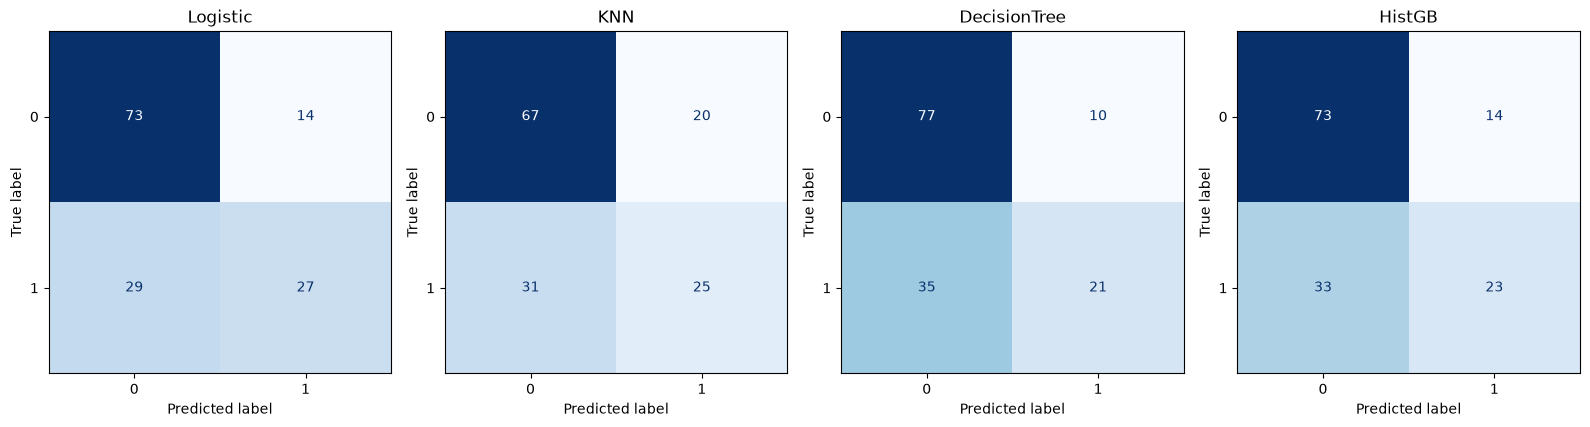

In [11]:
plt.figure(figsize=(16, 4))
for i, (name, model) in enumerate(classifiers, 1):
    ax = plt.subplot(1, 4, i)
    p = model.predict(x_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test["Survived"], p)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Remember
- **Higher is better:** accuracy, precision, recall, F1, AUC, R²
- **Lower is better:** MAE, MSE, RMSE, MAPE → sort with `ascending=True`
- **3+ classes:** add `average="macro"` to precision, recall and F1